In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
dataset = pd.read_csv("C:/Users/user/Downloads/classification data/Social_Network_Ads.csv").values
X = dataset[:,:-1]
y = dataset[:,-1]

In [3]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=1)

In [6]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=10, criterion='gini',
                            min_samples_split=5, bootstrap=True,
                            max_features='sqrt',random_state=1)
rf.fit(X_train, y_train)

,n_estimators,10
,criterion,'gini'
,max_depth,None
,min_samples_split,5
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [7]:
y_train_pred = rf.predict(X_train)
y_test_pred = rf.predict(X_test)

In [9]:
from sklearn.metrics import accuracy_score
acc_train = accuracy_score(y_train, y_train_pred)
acc_test = accuracy_score(y_test,y_test_pred)

print('train accuracy: ',acc_train * 100)
print('test accuracy: ', acc_test * 100)

train accuracy:  95.66666666666667
test accuracy:  89.0


In [ ]:
#(10,5): 95.7, 89.0

array([ 4.550e+01,  9.100e+04,  4.450e+01,  8.600e+04,  3.650e+01,
       -2.000e+00,  6.750e+04, -2.000e+00,  4.050e+01,  3.850e+01,
        3.750e+01, -2.000e+00, -2.000e+00, -2.000e+00, -2.000e+00,
        3.800e+01, -2.000e+00, -2.000e+00, -2.000e+00,  1.215e+05,
        3.400e+01,  1.100e+05, -2.000e+00, -2.000e+00,  1.075e+05,
       -2.000e+00, -2.000e+00, -2.000e+00,  4.150e+04, -2.000e+00,
        4.750e+01,  4.650e+01, -2.000e+00, -2.000e+00,  4.400e+04,
       -2.000e+00,  5.150e+01,  1.265e+05, -2.000e+00, -2.000e+00,
       -2.000e+00])

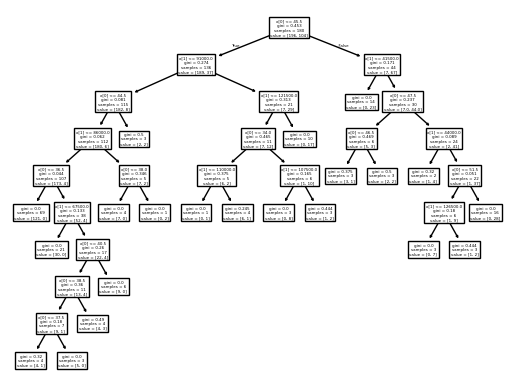

In [12]:
from sklearn.tree import plot_tree
plot_tree(rf.estimators_[1])
rf.estimators_[1].tree_.threshold

In [16]:
from sklearn.tree import export_text

# rf는 이미 랜덤 포레스트 모델로 fit되어 있어야 합니다
tree = rf.estimators_[1]  # 두 번째 개별 결정트리(estimator)
feature_names = ['age', 'salary']

print(export_text(tree, feature_names=feature_names))

|--- age <= 45.50
|   |--- salary <= 91000.00
|   |   |--- age <= 44.50
|   |   |   |--- salary <= 86000.00
|   |   |   |   |--- age <= 36.50
|   |   |   |   |   |--- class: 0.0
|   |   |   |   |--- age >  36.50
|   |   |   |   |   |--- salary <= 67500.00
|   |   |   |   |   |   |--- class: 0.0
|   |   |   |   |   |--- salary >  67500.00
|   |   |   |   |   |   |--- age <= 40.50
|   |   |   |   |   |   |   |--- age <= 38.50
|   |   |   |   |   |   |   |   |--- age <= 37.50
|   |   |   |   |   |   |   |   |   |--- class: 0.0
|   |   |   |   |   |   |   |   |--- age >  37.50
|   |   |   |   |   |   |   |   |   |--- class: 0.0
|   |   |   |   |   |   |   |--- age >  38.50
|   |   |   |   |   |   |   |   |--- class: 0.0
|   |   |   |   |   |   |--- age >  40.50
|   |   |   |   |   |   |   |--- class: 0.0
|   |   |   |--- salary >  86000.00
|   |   |   |   |--- age <= 38.00
|   |   |   |   |   |--- class: 0.0
|   |   |   |   |--- age >  38.00
|   |   |   |   |   |--- class: 1.0
|   |   |---

In [17]:
x0_min = X[:,0].min()-2
x0_max = X[:,0].max()+2

x1_min = X[:,1].min()-1000
x1_max = X[:,1].max()+1000

x0 = np.linspace(x0_min,x0_max,500)
x0 = np.linspace(x0_min,x0_max,500)

x1 = np.linspace(x1_min,x1_max,500)
x1 = np.linspace(x1_min,x1_max,500)

X0,X1 = np.meshgrid(x0,x1)

In [18]:
X0_1D = X0.reshape(-1,1)
X1_1D = X1.reshape(-1,1)
X0_X1 = np.concatenate((X0_1D,X1_1D),axis=1)

In [20]:
y_grid = rf.predict(X0_X1)

In [ ]:
from matplotlib.colors import ListedColormap
class_color = ListedColormap(['red', 'green'])
y_dt = y_grid.reshape(X0.shape)
plt.contourf(X0, X1, y_dt, cmap=class_color, alpha=0.3)

X0_train = X_train[y_train==0,:]
X1_train= X_train[y_train ==1,:]

plt.scatter(X0_train[:,0], X0_train[:,1], color='red', label='not purchased')
plt.scatter(X1_train[:,0], X1_train[:,1], color='green', marker='s', label='purchased')
plt.legend()